# 02 - Baseline Text Classifiers

This notebook trains and evaluates two classical baselines before CamemBERT:

1. TF-IDF + Logistic Regression
2. TF-IDF + Linear SVM

Main selection metric: **macro_f1**.
Safety-critical focus: recall on `urgence`, `avis_medical_personnalise`, `sensible_reformulable`.

In [14]:
from pathlib import Path
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import LabelEncoder
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 180)

RANDOM_STATE = 42

LABEL_ORDER = [
    "information_generale",
    "sensible_reformulable",
    "avis_medical_personnalise",
    "urgence",
    "hors_perimetre",
]

DANGEROUS_PAIRS = {
    ("urgence", "information_generale"),
    ("urgence", "sensible_reformulable"),
    ("avis_medical_personnalise", "information_generale"),
    ("avis_medical_personnalise", "sensible_reformulable"),
}


def resolve_root() -> Path:
    cwd = Path.cwd().resolve()
    if (cwd / "data").exists() and (cwd / "models").exists():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data").exists():
        return cwd.parent
    return cwd


ROOT = resolve_root()
DATA_PROCESSED = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports" / "baselines"

LOGREG_DIR = MODELS_DIR / "baseline_tfidf_logreg"
SVM_DIR = MODELS_DIR / "baseline_tfidf_linear_svm"

for p in [LOGREG_DIR, SVM_DIR, REPORTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_PROCESSED / "train.csv"
VAL_PATH = DATA_PROCESSED / "val.csv"
TEST_PATH = DATA_PROCESSED / "test.csv"

print("ROOT:", ROOT)
print("TRAIN:", TRAIN_PATH)
print("VAL:", VAL_PATH)
print("TEST:", TEST_PATH)
print("MODELS:", MODELS_DIR)
print("REPORTS:", REPORTS_DIR)

ROOT: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot
TRAIN: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\train.csv
VAL: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\val.csv
TEST: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\data\processed\test.csv
MODELS: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\models
REPORTS: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\reports\baselines


## Data loading

In [15]:
required_cols = ["text", "label", "topic", "source"]

for f in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not f.exists():
        raise FileNotFoundError(f"Missing split file: {f}")

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

for name, df_ in [("train", train_df), ("val", val_df), ("test", test_df)]:
    missing_cols = [c for c in required_cols if c not in df_.columns]
    if missing_cols:
        raise ValueError(f"{name} missing required columns: {missing_cols}")
    df_["text"] = df_["text"].astype(str).str.strip()

X_train, y_train = train_df["text"], train_df["label"]
X_val, y_val = val_df["text"], val_df["label"]
X_test, y_test = test_df["text"], test_df["label"]

print(f"train rows: {len(train_df):,}")
print(f"val rows  : {len(val_df):,}")
print(f"test rows : {len(test_df):,}")
print("label order expected:", LABEL_ORDER)
print("labels train:", sorted(y_train.unique()))

display(pd.DataFrame({
    "train": y_train.value_counts(),
    "val": y_val.value_counts(),
    "test": y_test.value_counts(),
}).fillna(0).astype(int))

train rows: 12,908
val rows  : 1,614
test rows : 1,614
label order expected: ['information_generale', 'sensible_reformulable', 'avis_medical_personnalise', 'urgence', 'hors_perimetre']
labels train: ['avis_medical_personnalise', 'hors_perimetre', 'information_generale', 'sensible_reformulable', 'urgence']


,train,val,test
label,,,
sensible_reformulable,4609,577,576
avis_medical_personnalise,3830,479,479
information_generale,2570,321,321
urgence,1618,202,203
hors_perimetre,281,35,35


## Utility functions

In [16]:
def evaluate_model(model, X, y_true, labels):
    y_pred = model.predict(X)

    acc = accuracy_score(y_true, y_pred)

    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )

    p_cls, r_cls, f_cls, s_cls = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )

    metrics = {
        "accuracy": float(acc),
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "macro_f1": float(macro_f1),
        "weighted_precision": float(weighted_p),
        "weighted_recall": float(weighted_r),
        "weighted_f1": float(weighted_f1),
    }

    for i, label in enumerate(labels):
        metrics[f"precision_{label}"] = float(p_cls[i])
        metrics[f"recall_{label}"] = float(r_cls[i])
        metrics[f"f1_{label}"] = float(f_cls[i])
        metrics[f"support_{label}"] = int(s_cls[i])

    return metrics, y_pred


def save_metrics(metrics_dict, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(metrics_dict, f, ensure_ascii=False, indent=2)


def plot_confusion_matrix(y_true, y_pred, labels, title, output_path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
    )
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    plt.xticks(rotation=20, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    fig.savefig(output_path, dpi=160)
    plt.show()


def extract_critical_errors(df_with_pred, model_name):
    mask = df_with_pred.apply(
        lambda r: (r["label"], r["predicted_label"]) in DANGEROUS_PAIRS,
        axis=1,
    )
    out = df_with_pred.loc[mask, ["text", "label", "predicted_label", "topic", "source"]].copy()
    out.insert(0, "model_name", model_name)
    out.rename(columns={"label": "true_label"}, inplace=True)
    return out


def save_model_config(path, model_type, vectorizer_params, classifier_params, label_order):
    cfg = {
        "model_type": model_type,
        "vectorizer_parameters": vectorizer_params,
        "classifier_parameters": classifier_params,
        "label_order": label_order,
        "training_date": datetime.now(timezone.utc).isoformat(),
        "train_file": str(TRAIN_PATH.as_posix()),
        "val_file": str(VAL_PATH.as_posix()),
        "test_file": str(TEST_PATH.as_posix()),
        "random_state": RANDOM_STATE,
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(cfg, f, ensure_ascii=False, indent=2)


def save_classification_report_csv(y_true, y_pred, labels, path):
    report = classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
    rows = []
    for lbl in labels:
        row = report.get(lbl, {})
        rows.append({
            "label": lbl,
            "precision": row.get("precision", 0.0),
            "recall": row.get("recall", 0.0),
            "f1-score": row.get("f1-score", 0.0),
            "support": row.get("support", 0),
        })
    pd.DataFrame(rows).to_csv(path, index=False)


required_metric_keys = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1",
]

print("Functions ready.")

Functions ready.


## Build baselines

In [17]:
logreg_vectorizer_params = {
    "lowercase": True,
    "strip_accents": "unicode",
    "ngram_range": (1, 2),
    "max_features": 50000,
    "min_df": 2,
    "max_df": 0.95,
    "sublinear_tf": True,
}

logreg_classifier_params = {
    "max_iter": 3000,
    "class_weight": "balanced",
    "solver": "liblinear",
    "random_state": RANDOM_STATE,
}

svm_vectorizer_params = {
    "lowercase": True,
    "strip_accents": "unicode",
    "ngram_range": (1, 2),
    "max_features": 70000,
    "min_df": 2,
    "max_df": 0.95,
    "sublinear_tf": True,
}

svm_classifier_params = {
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
}

logreg_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**logreg_vectorizer_params)),
    ("clf", OneVsRestClassifier(LogisticRegression(**logreg_classifier_params))),
])

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**svm_vectorizer_params)),
    ("clf", LinearSVC(**svm_classifier_params)),
])

print("Baselines initialized.")

Baselines initialized.


## Train and evaluate baselines

Training Logistic Regression baseline...


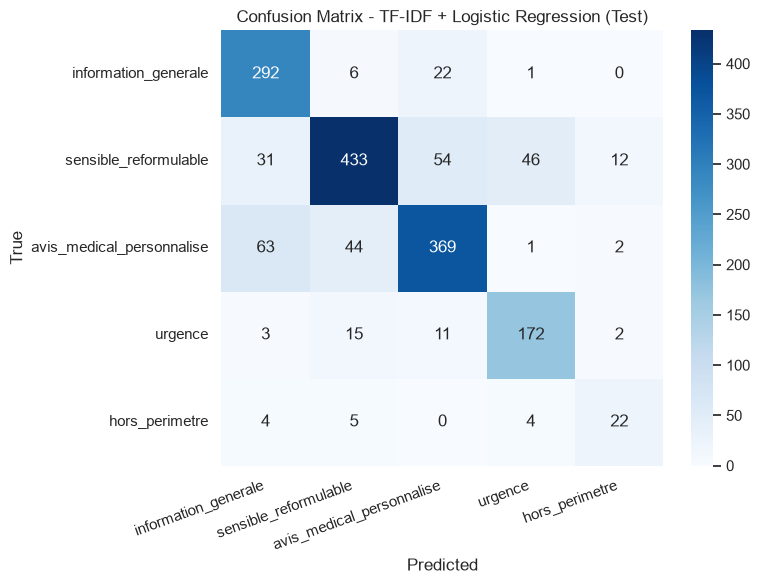

Training Linear SVM baseline...


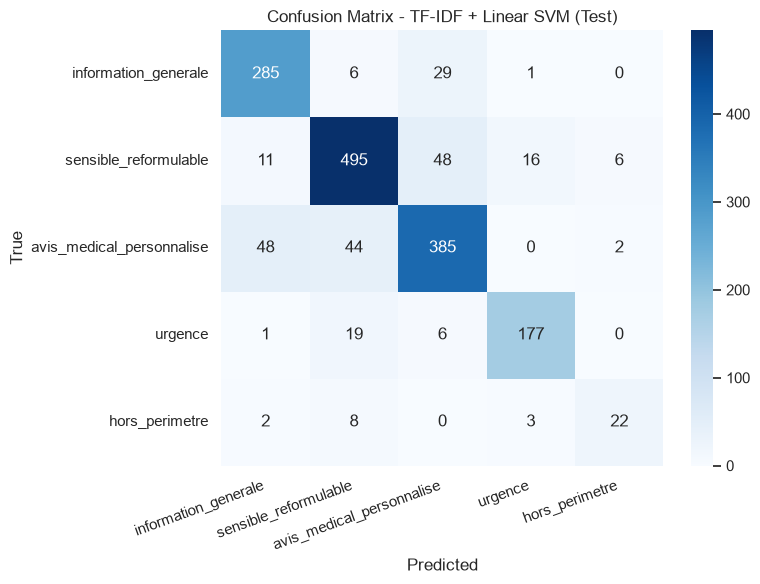

Training and evaluation complete.
Validation macro_f1:
  tfidf_logreg    : 0.7581
  tfidf_linear_svm: 0.787


In [18]:
results = {}
all_critical_errors = []

# Label encoder artifacts (same fixed order for both models)
label_encoder = LabelEncoder()
label_encoder.fit(LABEL_ORDER)

# -------- Logistic Regression --------
print("Training Logistic Regression baseline...")
logreg_pipeline.fit(X_train, y_train)

logreg_val_metrics, logreg_val_pred = evaluate_model(logreg_pipeline, X_val, y_val, LABEL_ORDER)
logreg_test_metrics, logreg_test_pred = evaluate_model(logreg_pipeline, X_test, y_test, LABEL_ORDER)

save_metrics(logreg_val_metrics, REPORTS_DIR / "baseline_logreg_val_metrics.json")
save_metrics(logreg_test_metrics, REPORTS_DIR / "baseline_logreg_test_metrics.json")

save_classification_report_csv(
    y_test, logreg_test_pred, LABEL_ORDER,
    REPORTS_DIR / "classification_report_logreg_test.csv"
)

plot_confusion_matrix(
    y_test,
    logreg_test_pred,
    LABEL_ORDER,
    "Confusion Matrix - TF-IDF + Logistic Regression (Test)",
    REPORTS_DIR / "confusion_matrix_logreg_test.png",
)

logreg_test_df = test_df.copy()
logreg_test_df["predicted_label"] = logreg_test_pred
logreg_critical = extract_critical_errors(logreg_test_df, "tfidf_logreg")
all_critical_errors.append(logreg_critical)

joblib.dump(logreg_pipeline, LOGREG_DIR / "model.joblib")
joblib.dump(label_encoder, LOGREG_DIR / "label_encoder.joblib")

save_model_config(
    LOGREG_DIR / "config.json",
    model_type="tfidf_logreg",
    vectorizer_params=logreg_vectorizer_params,
    classifier_params=logreg_classifier_params,
    label_order=LABEL_ORDER,
)

results["tfidf_logreg"] = {
    "val": logreg_val_metrics,
    "test": logreg_test_metrics,
    "critical_errors": int(len(logreg_critical)),
}

# -------- Linear SVM --------
print("Training Linear SVM baseline...")
svm_pipeline.fit(X_train, y_train)

svm_val_metrics, svm_val_pred = evaluate_model(svm_pipeline, X_val, y_val, LABEL_ORDER)
svm_test_metrics, svm_test_pred = evaluate_model(svm_pipeline, X_test, y_test, LABEL_ORDER)

save_metrics(svm_val_metrics, REPORTS_DIR / "baseline_svm_val_metrics.json")
save_metrics(svm_test_metrics, REPORTS_DIR / "baseline_svm_test_metrics.json")

save_classification_report_csv(
    y_test, svm_test_pred, LABEL_ORDER,
    REPORTS_DIR / "classification_report_svm_test.csv"
)

plot_confusion_matrix(
    y_test,
    svm_test_pred,
    LABEL_ORDER,
    "Confusion Matrix - TF-IDF + Linear SVM (Test)",
    REPORTS_DIR / "confusion_matrix_svm_test.png",
)

svm_test_df = test_df.copy()
svm_test_df["predicted_label"] = svm_test_pred
svm_critical = extract_critical_errors(svm_test_df, "tfidf_linear_svm")
all_critical_errors.append(svm_critical)

joblib.dump(svm_pipeline, SVM_DIR / "model.joblib")
joblib.dump(label_encoder, SVM_DIR / "label_encoder.joblib")

save_model_config(
    SVM_DIR / "config.json",
    model_type="tfidf_linear_svm",
    vectorizer_params=svm_vectorizer_params,
    classifier_params=svm_classifier_params,
    label_order=LABEL_ORDER,
)

results["tfidf_linear_svm"] = {
    "val": svm_val_metrics,
    "test": svm_test_metrics,
    "critical_errors": int(len(svm_critical)),
}

print("Training and evaluation complete.")
print("Validation macro_f1:")
print("  tfidf_logreg    :", round(results["tfidf_logreg"]["val"]["macro_f1"], 4))
print("  tfidf_linear_svm:", round(results["tfidf_linear_svm"]["val"]["macro_f1"], 4))

## Critical errors and model comparison

In [19]:
critical_errors_df = pd.concat(all_critical_errors, ignore_index=True)
critical_errors_path = REPORTS_DIR / "critical_errors_report.csv"
critical_errors_df.to_csv(critical_errors_path, index=False)
print(f"Saved: {critical_errors_path} | rows={len(critical_errors_df)}")

comparison_rows = []
for model_name in ["tfidf_logreg", "tfidf_linear_svm"]:
    tm = results[model_name]["test"]
    comparison_rows.append({
        "model_name": model_name,
        "accuracy": tm["accuracy"],
        "macro_f1": tm["macro_f1"],
        "weighted_f1": tm["weighted_f1"],
        "recall_information_generale": tm["recall_information_generale"],
        "recall_sensible_reformulable": tm["recall_sensible_reformulable"],
        "recall_avis_medical_personnalise": tm["recall_avis_medical_personnalise"],
        "recall_urgence": tm["recall_urgence"],
        "recall_hors_perimetre": tm["recall_hors_perimetre"],
        "number_of_critical_errors": results[model_name]["critical_errors"],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values(
    by=["macro_f1", "recall_urgence", "number_of_critical_errors"],
    ascending=[False, False, True],
).reset_index(drop=True)

comparison_path = REPORTS_DIR / "baseline_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("\nTest comparison:")
display(comparison_df)
print(f"Saved: {comparison_path}")

best_baseline = comparison_df.iloc[0]["model_name"]
print("BEST_BASELINE (test):", best_baseline)
print("Selection rule: macro_f1 desc, recall_urgence desc, critical_errors asc")

print("\nValidation macro_f1 (for development selection only):")
print("  tfidf_logreg    :", round(results["tfidf_logreg"]["val"]["macro_f1"], 4))
print("  tfidf_linear_svm:", round(results["tfidf_linear_svm"]["val"]["macro_f1"], 4))

Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\reports\baselines\critical_errors_report.csv | rows=237

Test comparison:


,model_name,accuracy,macro_f1,weighted_f1,recall_information_generale,recall_sensible_reformulable,recall_avis_medical_personnalise,recall_urgence,recall_hors_perimetre,number_of_critical_errors
0,tfidf_linear_svm,0.845105,0.818136,0.844765,0.887850,0.859375,0.803758,0.871921,0.628571,112
1,tfidf_logreg,0.798017,0.763637,0.797747,0.909657,0.751736,0.770355,0.847291,0.628571,125


Saved: C:\Users\223114186\Documents\chatbot_ia\icu_chatbot\reports\baselines\baseline_comparison.csv
BEST_BASELINE (test): tfidf_linear_svm
Selection rule: macro_f1 desc, recall_urgence desc, critical_errors asc

Validation macro_f1 (for development selection only):
  tfidf_logreg    : 0.7581
  tfidf_linear_svm: 0.787


## Manual prediction test

In [20]:
manual_examples = [
    "C’est quoi une ventilation mécanique ?",
    "Mon père est intubé, pouvez-vous m’expliquer ce que cela signifie ?",
    "Ma mère a une saturation à 82, est-ce grave ?",
    "Le scope sonne et mon père ne respire plus.",
    "Peux-tu m’aider à réserver un taxi ?",
]

for i, text in enumerate(manual_examples, 1):
    logreg_pred = logreg_pipeline.predict([text])[0]
    svm_pred = svm_pipeline.predict([text])[0]

    proba = logreg_pipeline.predict_proba([text])[0]
    classes = list(logreg_pipeline.named_steps["clf"].classes_)
    top_idx = int(np.argmax(proba))
    logreg_conf = float(proba[top_idx])

    print("-" * 90)
    print(f"Example {i}")
    print("text:", text)
    print("LogReg prediction:", logreg_pred)
    print("LogReg confidence:", round(logreg_conf, 4), "| class:", classes[top_idx])
    print("SVM prediction:", svm_pred)

    if hasattr(svm_pipeline.named_steps["clf"], "decision_function"):
        scores = svm_pipeline.decision_function([text])[0]
        svm_classes = list(svm_pipeline.named_steps["clf"].classes_)
        score_df = pd.DataFrame({"label": svm_classes, "decision_score": scores})
        score_df = score_df.sort_values("decision_score", ascending=False).reset_index(drop=True)
        print("SVM top decision scores:")
        display(score_df.head(3))

------------------------------------------------------------------------------------------
Example 1
text: C’est quoi une ventilation mécanique ?
LogReg prediction: information_generale
LogReg confidence: 0.5545 | class: information_generale
SVM prediction: information_generale
SVM top decision scores:


,label,decision_score
0,information_generale,0.817321
1,avis_medical_personnalise,-0.800840
2,sensible_reformulable,-0.926998


------------------------------------------------------------------------------------------
Example 2
text: Mon père est intubé, pouvez-vous m’expliquer ce que cela signifie ?
LogReg prediction: avis_medical_personnalise
LogReg confidence: 0.4572 | class: avis_medical_personnalise
SVM prediction: information_generale
SVM top decision scores:


,label,decision_score
0,information_generale,0.134041
1,avis_medical_personnalise,-0.200835
2,sensible_reformulable,-0.930728


------------------------------------------------------------------------------------------
Example 3
text: Ma mère a une saturation à 82, est-ce grave ?
LogReg prediction: information_generale
LogReg confidence: 0.4114 | class: information_generale
SVM prediction: information_generale
SVM top decision scores:


,label,decision_score
0,information_generale,-0.238030
1,sensible_reformulable,-0.256204
2,avis_medical_personnalise,-0.662204


------------------------------------------------------------------------------------------
Example 4
text: Le scope sonne et mon père ne respire plus.
LogReg prediction: information_generale
LogReg confidence: 0.3462 | class: information_generale
SVM prediction: sensible_reformulable
SVM top decision scores:


,label,decision_score
0,sensible_reformulable,-0.157234
1,information_generale,-0.398193
2,avis_medical_personnalise,-0.671566


------------------------------------------------------------------------------------------
Example 5
text: Peux-tu m’aider à réserver un taxi ?
LogReg prediction: information_generale
LogReg confidence: 0.495 | class: information_generale
SVM prediction: information_generale
SVM top decision scores:


,label,decision_score
0,information_generale,0.354377
1,avis_medical_personnalise,-0.387217
2,hors_perimetre,-0.685986


## Final status

In [21]:
expected_files = [
    LOGREG_DIR / "model.joblib",
    LOGREG_DIR / "label_encoder.joblib",
    LOGREG_DIR / "config.json",
    SVM_DIR / "model.joblib",
    SVM_DIR / "label_encoder.joblib",
    SVM_DIR / "config.json",
    REPORTS_DIR / "baseline_logreg_val_metrics.json",
    REPORTS_DIR / "baseline_logreg_test_metrics.json",
    REPORTS_DIR / "baseline_svm_val_metrics.json",
    REPORTS_DIR / "baseline_svm_test_metrics.json",
    REPORTS_DIR / "baseline_comparison.csv",
    REPORTS_DIR / "confusion_matrix_logreg_test.png",
    REPORTS_DIR / "confusion_matrix_svm_test.png",
    REPORTS_DIR / "classification_report_logreg_test.csv",
    REPORTS_DIR / "classification_report_svm_test.csv",
    REPORTS_DIR / "critical_errors_report.csv",
]

blocking_reasons = []
missing_files = [str(p.as_posix()) for p in expected_files if not p.exists()]
if missing_files:
    blocking_reasons.append(f"Missing files: {missing_files}")

for model_name in ["tfidf_logreg", "tfidf_linear_svm"]:
    for split_name in ["val", "test"]:
        m = results.get(model_name, {}).get(split_name, {})
        missing_metrics = [k for k in required_metric_keys if k not in m]
        if missing_metrics:
            blocking_reasons.append(
                f"{model_name} {split_name} missing metrics: {missing_metrics}"
            )

ready_for_camembert = "YES" if len(blocking_reasons) == 0 else "NO"

print("=" * 70)
print("BASELINE_TRAINING_DONE = YES")
print("FILES_CREATED:")
print("models/baseline_tfidf_logreg/model.joblib")
print("models/baseline_tfidf_linear_svm/model.joblib")
print("reports/baselines/baseline_comparison.csv")
print("reports/baselines/critical_errors_report.csv")
print(f"BEST_BASELINE = {best_baseline}")
print(f"READY_FOR_CAMEMBERT = {ready_for_camembert}")

if ready_for_camembert == "NO":
    print("BLOCKING_REASONS:")
    for r in blocking_reasons:
        print(f"- {r}")
print("=" * 70)

BASELINE_TRAINING_DONE = YES
FILES_CREATED:
models/baseline_tfidf_logreg/model.joblib
models/baseline_tfidf_linear_svm/model.joblib
reports/baselines/baseline_comparison.csv
reports/baselines/critical_errors_report.csv
BEST_BASELINE = tfidf_linear_svm
READY_FOR_CAMEMBERT = YES
